In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv


Null Hypothesis:

There is no significant difference in the average "scam-likeness score" between fake and real job postings.

Alternate Hypothesis:

Fake job postings have a significantly higher average scam-likeness score than real job postings.

In [2]:
df = pd.read_csv("/kaggle/input/real-or-fake-fake-jobposting-prediction/fake_job_postings.csv").set_index('job_id')
df.head()

,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
job_id,,,,,,,,,,,,,,,,,
1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [3]:
import re
# Copy to preserve original
df_clean = df.copy()

# ------------------------
# Basic Text Cleaning
# ------------------------

text_cols = ['company_profile', 'description', 'requirements', 'benefits']
for col in text_cols:
    df_clean[col] = df_clean[col].astype(str).str.lower().str.strip()

# ------------------------
# Feature Extraction
# ------------------------

# 1. Has company profile (binary)
df_clean['has_company_profile'] = df_clean['company_profile'].apply(lambda x: 0 if x in ['nan', ''] else 1)

# 2. Company profile length (in words)
df_clean['company_profile_length'] = df_clean['company_profile'].apply(lambda x: len(x.split()) if x != 'nan' else 0)

# 3. Website in profile (binary)
df_clean['has_website_in_profile'] = df_clean['company_profile'].apply(lambda x: 1 if re.search(r'https?://', x) else 0)

generic_keywords = [
    'great opportunity', 'quick hire', 'no experience', 'work from home',
    'easy job', 'urgent need', 'flexible hours', 'limited openings'
]

contact_phrases = [
    'contact us', 'apply now', 'reach out', 'email your cv', 'send your resume',
    'get in touch', 'respond immediately', 'available now'
]

# Compile regex patterns
generic_pattern = re.compile('|'.join(generic_keywords), re.IGNORECASE)
contact_pattern = re.compile('|'.join(contact_phrases), re.IGNORECASE)

# Apply patterns to extract counts
df_clean['num_generic_words'] = df_clean['description'].apply(
    lambda x: len(generic_pattern.findall(x)) if x != 'nan' else 0
)

df_clean['num_contact_phrases'] = df_clean['description'].apply(
    lambda x: len(contact_pattern.findall(x)) if x != 'nan' else 0
)


# 5. CV request (binary)
cv_keywords = ['send.*cv', 'email.*resume', 'attach.*cv', 'provide.*cv', 'submit.*resume']
cv_pattern = re.compile('|'.join(cv_keywords), re.IGNORECASE)
df_clean['cv_request'] = df_clean['description'].apply(lambda x: 1 if cv_pattern.search(x) else 0)

# 6. Description length (in words)
df_clean['description_length'] = df_clean['description'].apply(lambda x: len(x.split()) if x != 'nan' else 0)

# 7. Missing critical info (count)
critical_fields = ['company_profile', 'benefits', 'requirements']
df_clean['missing_critical_info'] = df_clean[critical_fields].apply(
    lambda row: sum(1 for val in row if val in ['nan', '']), axis=1
)

# ------------------------
# Final Feature DataFrame
# ------------------------

features = [
    'has_company_profile',
    'company_profile_length',
    'has_website_in_profile',
    'cv_request',
    'description_length',
    'missing_critical_info',
    'fraudulent'  # target variable
]

df_features = df_clean[features]

In [4]:
df_features

,has_company_profile,company_profile_length,has_website_in_profile,cv_request,description_length,missing_critical_info,fraudulent
job_id,,,,,,,
1,1,141,0,0,124,1,0
2,1,153,1,0,315,0,0
3,1,141,0,0,50,1,0
4,1,85,0,0,346,0,0
5,1,207,0,0,168,0,0
...,...,...,...,...,...,...,...
17876,1,290,0,0,226,0,0
17877,1,330,0,0,161,0,0
17878,1,32,0,0,171,1,0


In [5]:
df_features.describe()

,has_company_profile,company_profile_length,has_website_in_profile,cv_request,description_length,missing_critical_info,fraudulent
count,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000
mean,0.814989,92.553579,0.004754,0.035011,170.445973,0.739709,0.048434
std,0.388317,85.487278,0.068786,0.183813,123.304236,0.857893,0.214688
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,21.000000,0.000000,0.000000,87.000000,0.000000,0.000000
50%,1.000000,83.000000,0.000000,0.000000,146.000000,1.000000,0.000000
75%,1.000000,132.000000,0.000000,0.000000,224.000000,1.000000,0.000000
max,1.000000,885.000000,1.000000,1.000000,2115.000000,3.000000,1.000000


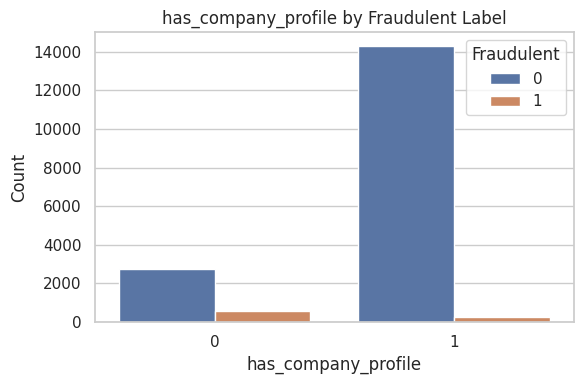

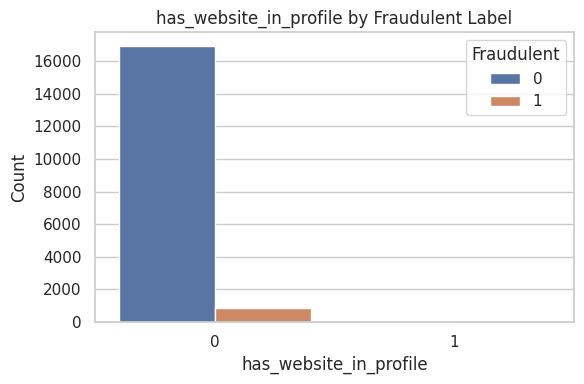

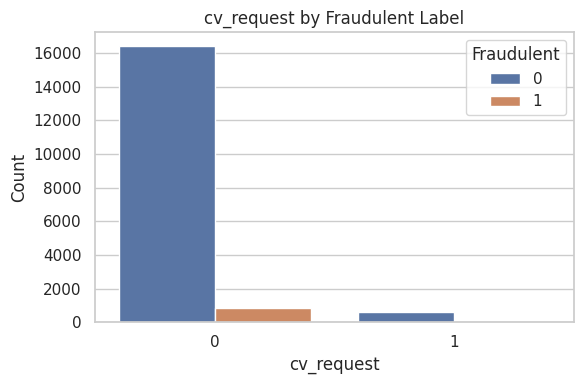

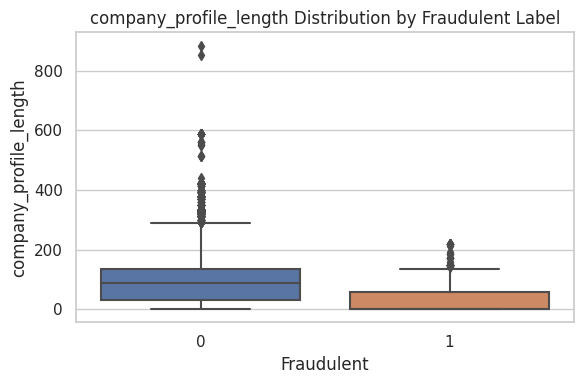

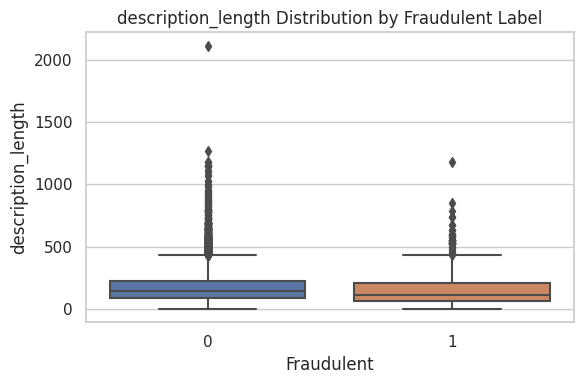

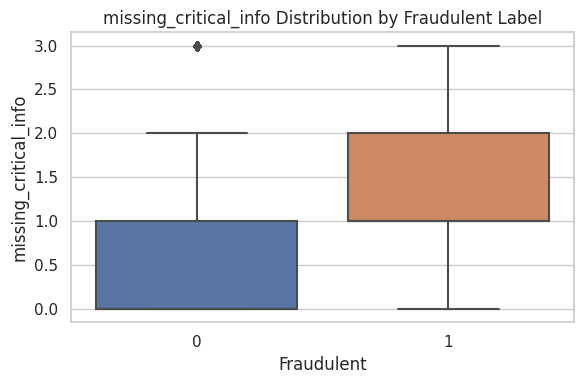

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

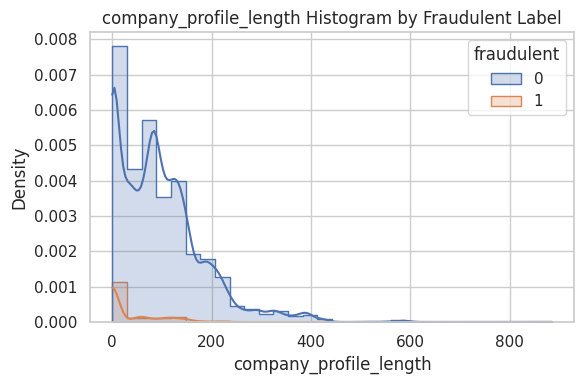

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

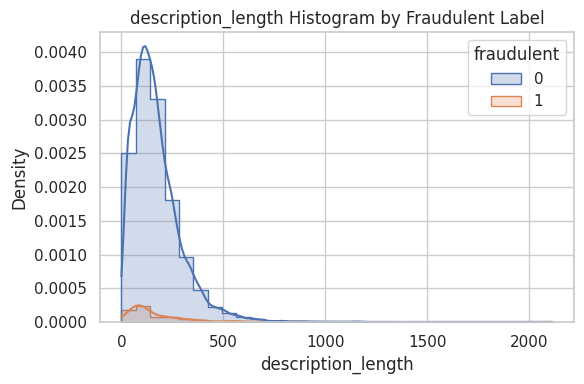

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

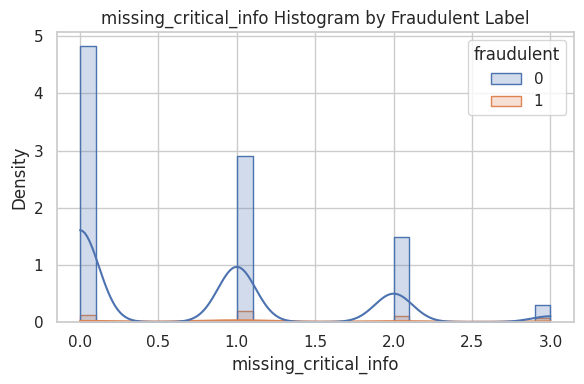

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set(style="whitegrid")

# Subset data
df_vis = df_clean[features]

# Separate binary and numerical features
binary_features = ['has_company_profile', 'has_website_in_profile', 'cv_request']
numeric_features = ['company_profile_length', 'description_length', 'missing_critical_info']

# Plot binary features as bar plots
for feature in binary_features:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df_vis, x=feature, hue='fraudulent')
    plt.title(f"{feature} by Fraudulent Label")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.legend(title='Fraudulent')
    plt.tight_layout()
    plt.show()

# Plot numeric features as boxplots grouped by fraud label
for feature in numeric_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df_vis, x='fraudulent', y=feature)
    plt.title(f"{feature} Distribution by Fraudulent Label")
    plt.xlabel("Fraudulent")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

# Optional: histogram overlay for numeric features
for feature in numeric_features:
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df_vis, x=feature, hue='fraudulent', bins=30, kde=True, element='step', stat='density')
    plt.title(f"{feature} Histogram by Fraudulent Label")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()


In [7]:
from scipy.stats import mannwhitneyu

real = df_clean[df_clean['fraudulent'] == 0]
fake = df_clean[df_clean['fraudulent'] == 1]

# Perform Mann-Whitney test and evaluate hypothesis
alpha = 0.05
test_results = []

for feature in features:
    stat, p = mannwhitneyu(real[feature], fake[feature], alternative='two-sided')
    reject_null = p < alpha
    test_results.append({
        'feature': feature,
        'U_statistic': stat,
        'p_value': p,
        'alpha': alpha,
        'reject_null': reject_null,
        'interpretation': "Reject H₀" if reject_null else "Fail to Reject H₀"
    })

# Convert to DataFrame
results_df = pd.DataFrame(test_results)

# Print results
print("Mann-Whitney U Test Hypothesis Evaluation:\n")
print(results_df[['feature', 'p_value', 'alpha', 'interpretation']])

Mann-Whitney U Test Hypothesis Evaluation:

                  feature        p_value  alpha interpretation
0     has_company_profile   0.000000e+00   0.05      Reject H₀
1  company_profile_length  3.430935e-155   0.05      Reject H₀
2  has_website_in_profile   3.707983e-02   0.05      Reject H₀
3              cv_request   3.692426e-03   0.05      Reject H₀
4      description_length   6.592514e-10   0.05      Reject H₀
5   missing_critical_info   1.266629e-66   0.05      Reject H₀
6              fraudulent   0.000000e+00   0.05      Reject H₀


In [8]:
# Normalize features to 0-1 range for fair contribution
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_clean[features]), columns=features)

# Calculate scam-likeness score: higher means more scam-like
# We flip features that imply legitimacy (e.g. has_company_profile -> 1 - value)
df_scaled['scam_likeness_score'] = (
    (1 - df_scaled['has_company_profile']) +
    (1 - df_scaled['has_website_in_profile']) +
    df_scaled['cv_request'] +
    (1 - df_scaled['company_profile_length']) +
    df_scaled['missing_critical_info'] +
    (1 - df_scaled['description_length'])
) / 6  # Average of 6 normalized components

# Append target for analysis
df_scaled['fraudulent'] = df_clean['fraudulent'].values

In [9]:
from scipy.stats import ttest_ind

# Split the scam_likeness_score into two groups: real (0) and fake (1)
real_scores = df_scaled[df_scaled['fraudulent'] == 0]['scam_likeness_score']
fake_scores = df_scaled[df_scaled['fraudulent'] == 1]['scam_likeness_score']

# Perform independent two-sample t-test
t_stat, p_value = ttest_ind(fake_scores, real_scores, equal_var=False)

t_stat, p_value

(27.270369877655643, 1.2541207455878949e-120)

Thus Null Hypothesis is rejected as P-value < 0.05